<a href="https://colab.research.google.com/github/zogydinesh/ITA-0616/blob/main/program19.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Rows: 614  Columns: 13
Approved (Y): 422  Rejected (N): 192
Missing values: {'Gender': 13, 'Married': 3, 'Dependents': 15, 'Self_Employed': 32, 'LoanAmount': 22, 'Loan_Amount_Term': 14, 'Credit_History': 50} 

Train size: 491  Test size: 123 

Priors: N = 0.316, Y = 0.684

Confusion Matrix (rows = actual, columns = predicted):
              Rejected (N)  Approved (Y)
Rejected (N)            17            20
Approved (Y)             3            83

Test accuracy: 81.30%
(Saying 'Approved' for everyone would give 69.92%)

Class          Precision  Recall
Rejected (N)   0.85       0.46
Approved (Y)   0.81       0.97

Approval rate in the training data by Credit_History:
Credit_History
0.0     8.3% approved
1.0    78.8% approved

New applicant: Male, married, 1 dependent, graduate, income 5000, co-income 1500,
               loan 130, 360 months, credit history 1, urban
  P(Rejected) = 0.196   P(Approved) = 0.804
Predicted: Approved (Y)


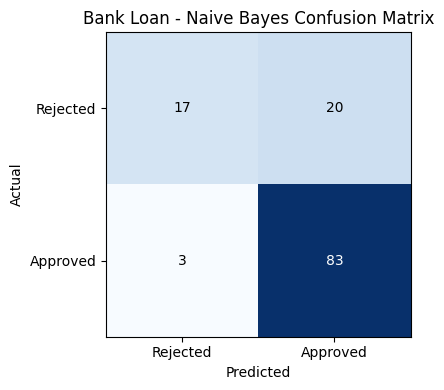

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Dataset: Loan Prediction (bank loan applications) - program19.csv, used as it is
# Loan_Status: Y = loan approved, N = loan rejected

# ---- 1. Load CSV ----
df = pd.read_csv('program19.csv')
print("Rows:", len(df), " Columns:", df.shape[1])
print("Approved (Y):", int((df['Loan_Status'] == 'Y').sum()), " Rejected (N):", int((df['Loan_Status'] == 'N').sum()))
missing = df.isna().sum()
print("Missing values:", missing[missing > 0].to_dict(), "\n")

cat_cols = ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed',
            'Credit_History', 'Loan_Amount_Term', 'Property_Area']      # category columns
num_cols = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount']      # number columns
classes = ['N', 'Y']

# ---- 2. Train / test split (80% / 20%) ----
np.random.seed(42)
idx = np.random.permutation(len(df))
split = int(0.8 * len(df))
train, test = df.iloc[idx[:split]].copy(), df.iloc[idx[split:]].copy()
print("Train size:", len(train), " Test size:", len(test), "\n")

# ---- 3. Fill missing values using TRAINING data only ----
for c in cat_cols:
    mode = train[c].mode()[0]
    train[c] = train[c].fillna(mode).astype(str)
    test[c] = test[c].fillna(mode).astype(str)

for c in num_cols:
    med = train[c].median()
    train[c] = train[c].fillna(med)
    test[c] = test[c].fillna(med)
    train[c] = np.log1p(train[c])          # log makes the skewed income/loan amounts bell-shaped
    test[c] = np.log1p(test[c])

# ---- 4. Training Naive Bayes (category columns + number columns) ----
ytr = train['Loan_Status'].values
prior, cat_prob, mean, var = {}, {}, {}, {}
for k in classes:
    rows = train[ytr == k]
    prior[k] = len(rows) / len(train)                                   # P(class)
    for c in cat_cols:
        values = sorted(train[c].unique())
        counts = rows[c].value_counts()
        # P(value | class) with Laplace smoothing (+1) so no probability is ever 0
        cat_prob[(k, c)] = {v: (counts.get(v, 0) + 1) / (len(rows) + len(values)) for v in values}
    mean[k] = rows[num_cols].mean().values
    var[k] = rows[num_cols].var().values + 1e-9

print(f"Priors: N = {prior['N']:.3f}, Y = {prior['Y']:.3f}")

# ---- 5. Prediction ----
def log_gaussian(x, m, v):
    return -0.5 * np.log(2 * np.pi * v) - ((x - m) ** 2) / (2 * v)

def class_scores(row):
    scores = {}
    for k in classes:
        s = np.log(prior[k])
        for c in cat_cols:
            s += np.log(cat_prob[(k, c)].get(row[c], 1e-6))
        s += np.sum(log_gaussian(row[num_cols].values.astype(float), mean[k], var[k]))
        scores[k] = s
    return scores

def predict(row):
    s = class_scores(row)
    return max(s, key=s.get)

pred = np.array([predict(r) for _, r in test.iterrows()])
yte = test['Loan_Status'].values

# ---- 6. Confusion matrix ----
cm = np.zeros((2, 2), dtype=int)
for a, p in zip(yte, pred):
    cm[classes.index(a), classes.index(p)] += 1

names = ['Rejected (N)', 'Approved (Y)']
print("\nConfusion Matrix (rows = actual, columns = predicted):")
print(pd.DataFrame(cm, index=names, columns=names))

# ---- 7. Accuracy, precision, recall ----
print(f"\nTest accuracy: {np.trace(cm) / cm.sum() * 100:.2f}%")
print(f"(Saying 'Approved' for everyone would give {np.mean(yte == 'Y') * 100:.2f}%)")
print("\nClass          Precision  Recall")
for i, n_ in enumerate(names):
    prec = cm[i, i] / cm[:, i].sum() if cm[:, i].sum() else 0
    rec = cm[i, i] / cm[i, :].sum() if cm[i, :].sum() else 0
    print(f"{n_:<14} {prec:.2f}       {rec:.2f}")

# ---- 8. Effect of Credit History ----
print("\nApproval rate in the training data by Credit_History:")
print(train.groupby('Credit_History')['Loan_Status'].apply(lambda s: f"{(s == 'Y').mean() * 100:.1f}% approved").to_string())

# ---- 9. Predict for a new applicant ----
new = pd.Series({'Gender': 'Male', 'Married': 'Yes', 'Dependents': '1', 'Education': 'Graduate',
                 'Self_Employed': 'No', 'Credit_History': '1.0', 'Loan_Amount_Term': '360.0',
                 'Property_Area': 'Urban', 'ApplicantIncome': np.log1p(5000),
                 'CoapplicantIncome': np.log1p(1500), 'LoanAmount': np.log1p(130)})
s = class_scores(new)
v = np.array([s['N'], s['Y']])
prob = np.exp(v - v.max())
prob /= prob.sum()

print("\nNew applicant: Male, married, 1 dependent, graduate, income 5000, co-income 1500,")
print("               loan 130, 360 months, credit history 1, urban")
print(f"  P(Rejected) = {prob[0]:.3f}   P(Approved) = {prob[1]:.3f}")
print("Predicted:", "Approved (Y)" if prob[1] > prob[0] else "Rejected (N)")

# ---- 10. Plot the confusion matrix ----
fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(cm, cmap='Blues')
ax.set_xticks([0, 1])
ax.set_xticklabels(['Rejected', 'Approved'])
ax.set_yticks([0, 1])
ax.set_yticklabels(['Rejected', 'Approved'])
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
ax.set_title('Bank Loan - Naive Bayes Confusion Matrix')
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha='center', va='center',
                color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.tight_layout()
plt.show()